<a href="https://colab.research.google.com/github/PPGCA-MLG/2026S2/blob/main/Aula_07/MLG_TF_MNIST_Classifier.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **MNIST Keras Classifiers**

Neste notebook, comparamos duas arquiteturas clássicas para classificação de dígitos manuscritos (`0` a `9`) do dataset **MNIST**:
1. **MLP (*Multi-Layer Perceptron*):** Rede totalmente conectada que recebe a imagem achatada como um vetor.
2. **ConvNet (CNN):** Rede Convolucional que preserva a estrutura espacial 2D da imagem para extrair padrões locais. Iremos montar várias versões desta arquitetura adicionando técnicas que melhorem a performance (MaxPooling, DropOut e BatchNormalization).

### 1. Exploração Visual do Dataset MNIST
Carregamos o conjunto de dados e exibimos uma amostra aleatória de 15 dígitos com seus respectivos rótulos.

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


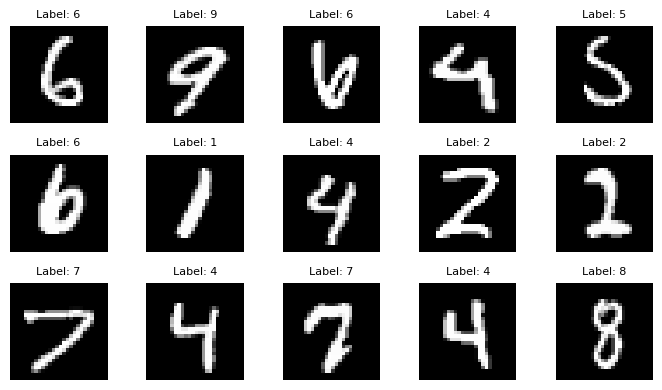

In [1]:
import matplotlib.pyplot as plt
import tensorflow as tf

# Carrega o dataset MNIST -> x_train: (60000, 28, 28), x_test: (10000, 28, 28)
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

# Seleciona 15 imagens aleatórias
import random
indices = random.sample(range(x_train.shape[0]), 15)
images = x_train[indices]
labels = y_train[indices]

fig, axes = plt.subplots(3, 5, figsize=(7,4))

for i, ax in enumerate(axes.flat):
    ax.imshow(images[i], cmap='gray')
    ax.set_title(f"Label: {labels[i]}",fontsize=8)
    ax.axis('off')

plt.tight_layout()
plt.show()


# Keras MLP - Multi-Layer Perceptron

Nesta etapa, cada imagem $28 \times 28$ é convertida em um vetor unidimensional de $784$ posições e processada por camadas densas (*Dense*) com regularização *Dropout*.



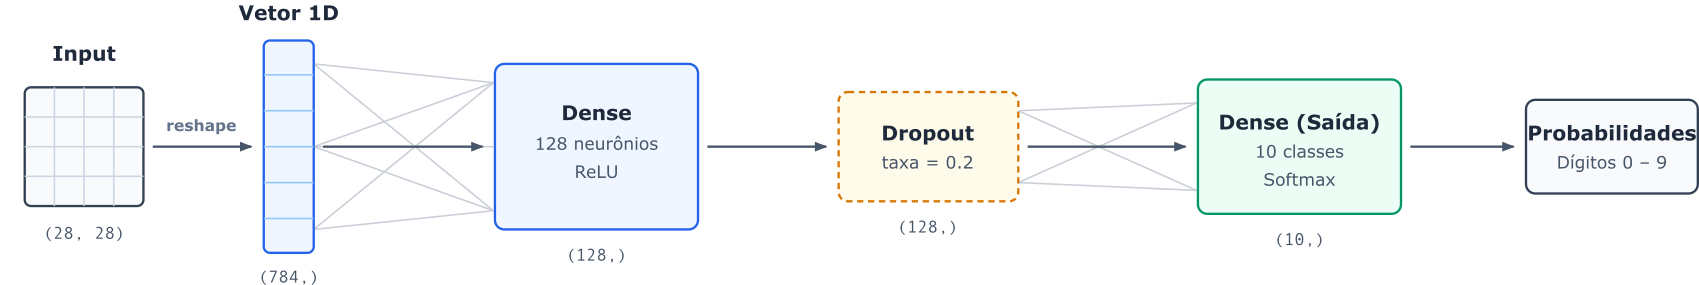

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 20s 9ms/step - accuracy: 0.9144 - loss: 0.2987 - val_accuracy: 0.9569 - val_loss: 0.1420
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 13s 5ms/step - accuracy: 0.9568 - loss: 0.1459 - val_accuracy: 0.9703 - val_loss: 0.0983
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9672 - loss: 0.1081 - val_accuracy: 0.9731 - val_loss: 0.0900
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.9739 - loss: 0.0866 - val_accuracy: 0.9749 - val_loss: 0.0831
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9764 - loss: 0.0746 - val_accuracy: 0.9785 - val_loss: 0.0708


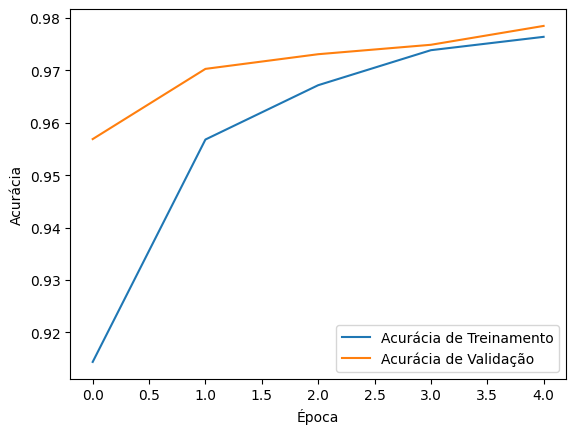

In [2]:
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np

# Carrega o dataset MNIST
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

# Normaliza os dados de entrada a [0,1]
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

# Lineariza as imagens 28x28 -> entrada passa de (N, 28, 28) para (N, 784)
x_train = x_train.reshape(-1, 784)
x_test = x_test.reshape(-1, 784)

# Define o modelo: entrada (784,) -> oculta (128,) -> saída (10 classes)
model = tf.keras.Sequential([
  tf.keras.layers.Dense(128, activation='relu', input_shape=(784,)),
  tf.keras.layers.Dropout(0.2),
  tf.keras.layers.Dense(10, activation='softmax')
])

# Compila o modelo
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

# Treina o modelo
history = model.fit(x_train, y_train, epochs=5, validation_data=(x_test, y_test))

# Plota o gráfico do treinamento
plt.plot(history.history['accuracy'], label='Acurácia de Treinamento')
plt.plot(history.history['val_accuracy'], label='Acurácia de Validação')
plt.xlabel('Época')
plt.ylabel('Acurácia')
plt.legend()
plt.show()


## Evaluation
Avaliação quantitativa no conjunto de teste (`10.000` amostras) utilizando precisão, revocação (*recall*) e *F1-score* por dígito.

In [3]:
from sklearn.metrics import classification_report

predictions = model.predict(x_test)
# Seleciona o índice de maior probabilidade
predicted_labels = np.argmax(predictions, axis=1)

print(classification_report(y_test, predicted_labels))

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
              precision    recall  f1-score   support

           0       0.98      0.98      0.98       980
           1       0.99      0.99      0.99      1135
           2       0.97      0.98      0.97      1032
           3       0.98      0.97      0.97      1010
           4       0.99      0.98      0.98       982
           5       0.97      0.98      0.97       892
           6       0.98      0.98      0.98       958
           7       0.97      0.98      0.98      1028
           8       0.97      0.97      0.97       974
           9       0.98      0.98      0.98      1009

    accuracy                           0.98     10000
   macro avg       0.98      0.98      0.98     10000
weighted avg       0.98      0.98      0.98     10000



## Predictions
Inspeção visual das predições do modelo MLP nas 5 primeiras imagens de teste.

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step


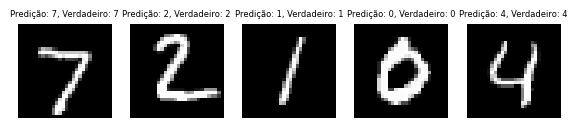

In [4]:
# Faz predições para algumas instâncias
predictions = model.predict(x_test[:5])

plt.figure(figsize=(7,2))

# Exibe as predições
for i in range(5):
    predicted_label = np.argmax(predictions[i])
    true_label = y_test[i]
    # print(f"Predição {i+1}: {predicted_label} (verdadeiro: {true_label})")

    # Exibe a imagem
    ax = plt.subplot(1,5,i+1)
    plt.imshow(x_test[i].reshape(28, 28), cmap='gray')
    plt.title(f"Predição: {predicted_label}, Verdadeiro: {true_label}",fontsize=6)
    plt.axis("off")

plt.show()



# Keras ConvNet

Aqui mantemos o formato bidimensional das imagens e aplicamos blocos de **Convolução (`Conv2D`) + Subamostragem (`MaxPooling2D`)** para extrair mapas de características espaciais antes da classificação final.



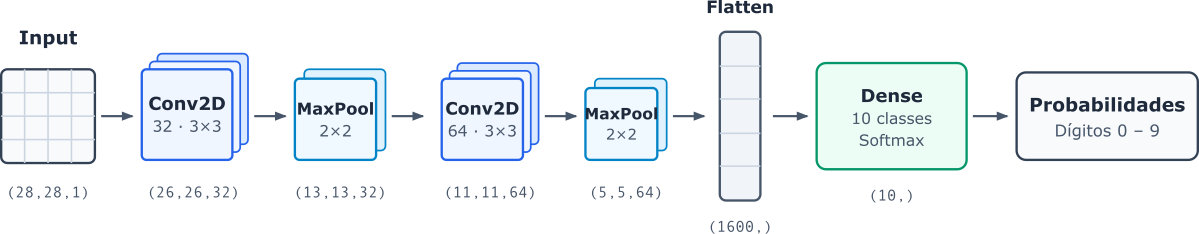

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 56s 29ms/step - accuracy: 0.9559 - loss: 0.1514 - val_accuracy: 0.9839 - val_loss: 0.0490
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 54s 29ms/step - accuracy: 0.9849 - loss: 0.0504 - val_accuracy: 0.9877 - val_loss: 0.0377
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 54s 29ms/step - accuracy: 0.9884 - loss: 0.0377 - val_accuracy: 0.9877 - val_loss: 0.0372
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 52s 28ms/step - accuracy: 0.9913 - loss: 0.0285 - val_accuracy: 0.9893 - val_loss: 0.0302
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 82s 28ms/step - accuracy: 0.9928 - loss: 0.0225 - val_accuracy: 0.9899 - val_loss: 0.0299


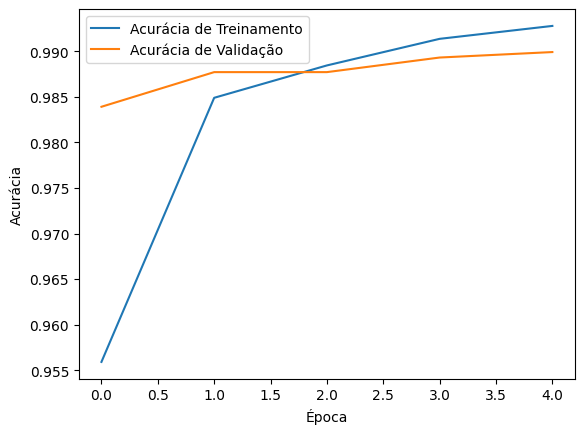

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step
              precision    recall  f1-score   support

           0       0.99      1.00      0.99       980
           1       0.99      1.00      0.99      1135
           2       0.99      0.99      0.99      1032
           3       0.99      0.99      0.99      1010
           4       0.99      1.00      0.99       982
           5       0.99      0.99      0.99       892
           6       1.00      0.98      0.99       958
           7       0.99      0.98      0.99      1028
           8       0.98      0.99      0.99       974
           9       0.99      0.98      0.99      1009

    accuracy                           0.99     10000
   macro avg       0.99      0.99      0.99     10000
weighted avg       0.99      0.99      0.99     10000

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step


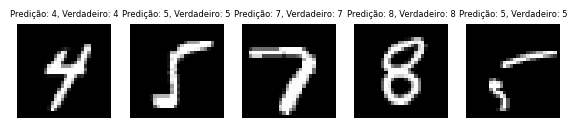

In [5]:
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import classification_report

# Carrega o dataset MNIST
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

# Normaliza os dados de entrada a [0,1]
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

# Adiciona uma dimensão para o 'canal' (Conv2D espera tensor de 4 dimensões: batch, altura, largura, canal) -> (N, 28, 28, 1)
x_train = np.expand_dims(x_train, -1)
x_test  = np.expand_dims(x_test, -1)

# Define o modelo convolucional (evolução espacial: 28x28x1 -> 26x26x32 -> 13x13x32 -> 11x11x64 -> 5x5x64 -> 1600 -> 10)
model = tf.keras.Sequential([
    tf.keras.layers.Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Conv2D(64, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(10, activation='softmax')
])

# Compila o modelo
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

# Treina o modelo
history = model.fit(x_train, y_train, epochs=5, validation_data=(x_test, y_test))

# Plota o gráfico do treinamento
plt.plot(history.history['accuracy'], label='Acurácia de Treinamento')
plt.plot(history.history['val_accuracy'], label='Acurácia de Validação')
plt.xlabel('Época')
plt.ylabel('Acurácia')
plt.legend()
plt.show()

# Avalia o modelo
predictions = model.predict(x_test)
predicted_labels = np.argmax(predictions, axis=1)
print(classification_report(y_test, predicted_labels))

# Faz predições para algumas instâncias aleatorias e exibe as imagens
indices = np.random.choice(len(x_test), 5, replace=False)
predictions = model.predict(x_test[indices])

plt.figure(figsize=(7,2))
for i, idx in enumerate(indices):
    predicted_label = np.argmax(predictions[i])
    true_label = y_test[idx]
    ax = plt.subplot(1,5,i+1)
    plt.imshow(x_test[idx].reshape(28, 28), cmap='gray')
    plt.title(f"Predição: {predicted_label}, Verdadeiro: {true_label}",fontsize=6)
    plt.axis("off")
plt.show()


# `Flatten`

Um ConvNet é apenas um extrator de características.
A classificação multiclasse se resolve na última camada:

1. Ela achata o mapa de características (`flatten`)
2. Faz uma camada linear para gerar logits
3. Aplica softmax para produzir probabilidades

Para ilustração, abaixo isolamos a camada `Flatten` em um tensor sintético para observar como ela transforma uma grade 2D `(1, 4, 4)` em um vetor 1D `(1, 16)`.

In [6]:
import tensorflow as tf

# Criarmos um tensor com valores aleatórios no formato (1,4,4)
x = tf.random.normal(shape=(1, 4, 4))
print(f"Tensor de dados aleatórios com shape {x.shape}:")
print(x)

# Achata (Flatten) os dados de entrada -> saída (1, 16)
y = tf.keras.layers.Flatten()(x)
print(f"Tensor de dados aleatórios com shape {y.shape}:")
print(y)


Tensor de dados aleatórios com shape (1, 4, 4):
tf.Tensor(
[[[ 1.7213452   1.0045967  -1.6966546   0.39425436]
  [ 0.25291687 -0.63229865  0.73669606 -0.2822712 ]
  [-0.44371212 -0.01612132 -0.8299233   2.5107563 ]
  [-0.52856416  0.3156237   0.8907616  -1.2497281 ]]], shape=(1, 4, 4), dtype=float32)
Tensor de dados aleatórios com shape (1, 16):
tf.Tensor(
[[ 1.7213452   1.0045967  -1.6966546   0.39425436  0.25291687 -0.63229865
   0.73669606 -0.2822712  -0.44371212 -0.01612132 -0.8299233   2.5107563
  -0.52856416  0.3156237   0.8907616  -1.2497281 ]], shape=(1, 16), dtype=float32)


# Dupla (`softmax` + `cross entropy`)

Dado um vetor de logits, as saídas da rede neural,

$$ \textbf{z} = [z_1,z_2,...,z_K]$$

onde $K$ é o número de classes, a **SoftMax** produz:

$$
\text{softmax}(z_i) =
\frac{e^{z_i}}{\sum_{j=1}^{K} e^{z_j}}
$$

A softmax aplica exponencial e normalização, convertendo esses valores em probabilidades. Com a normalização,

$$
\sum_i^K \text{softmax}(z_i) = 1
$$

transforma o problema de previsão em uma distribuição de probabilidade. A exponencial, tem a vantagem de *reforçar* as diferenças, isto é, se um valor é maior o torna ainda maior, facilitando a convergência.

$$ \textbf{z} = [2,1,-1]$$

$$ e^z = [7.39, 2.72, 0.37]$$

$$\sum_{j=1}^{3} e^{z_j} = 10,48$$

$$\text{Softmax}(z) \approx [0.70,\; 0.26,\; 0.04]$$

📌 Lembrando que empregamos a **entropia cruzada** como função de perda...

$$
ℒ = - \sum_{i=1}^{K} y_i \log(p_i)
$$

$$
ℒ =
- \sum_{i=1}^{K} y_i
\log\left(
\frac{e^{z_i}}{\sum_{j=1}^{K} e^{z_j}}
\right)
$$

A dupla **(softmax + cross entropy)** é padrão de quase todas as redes convolucionais para classificação.


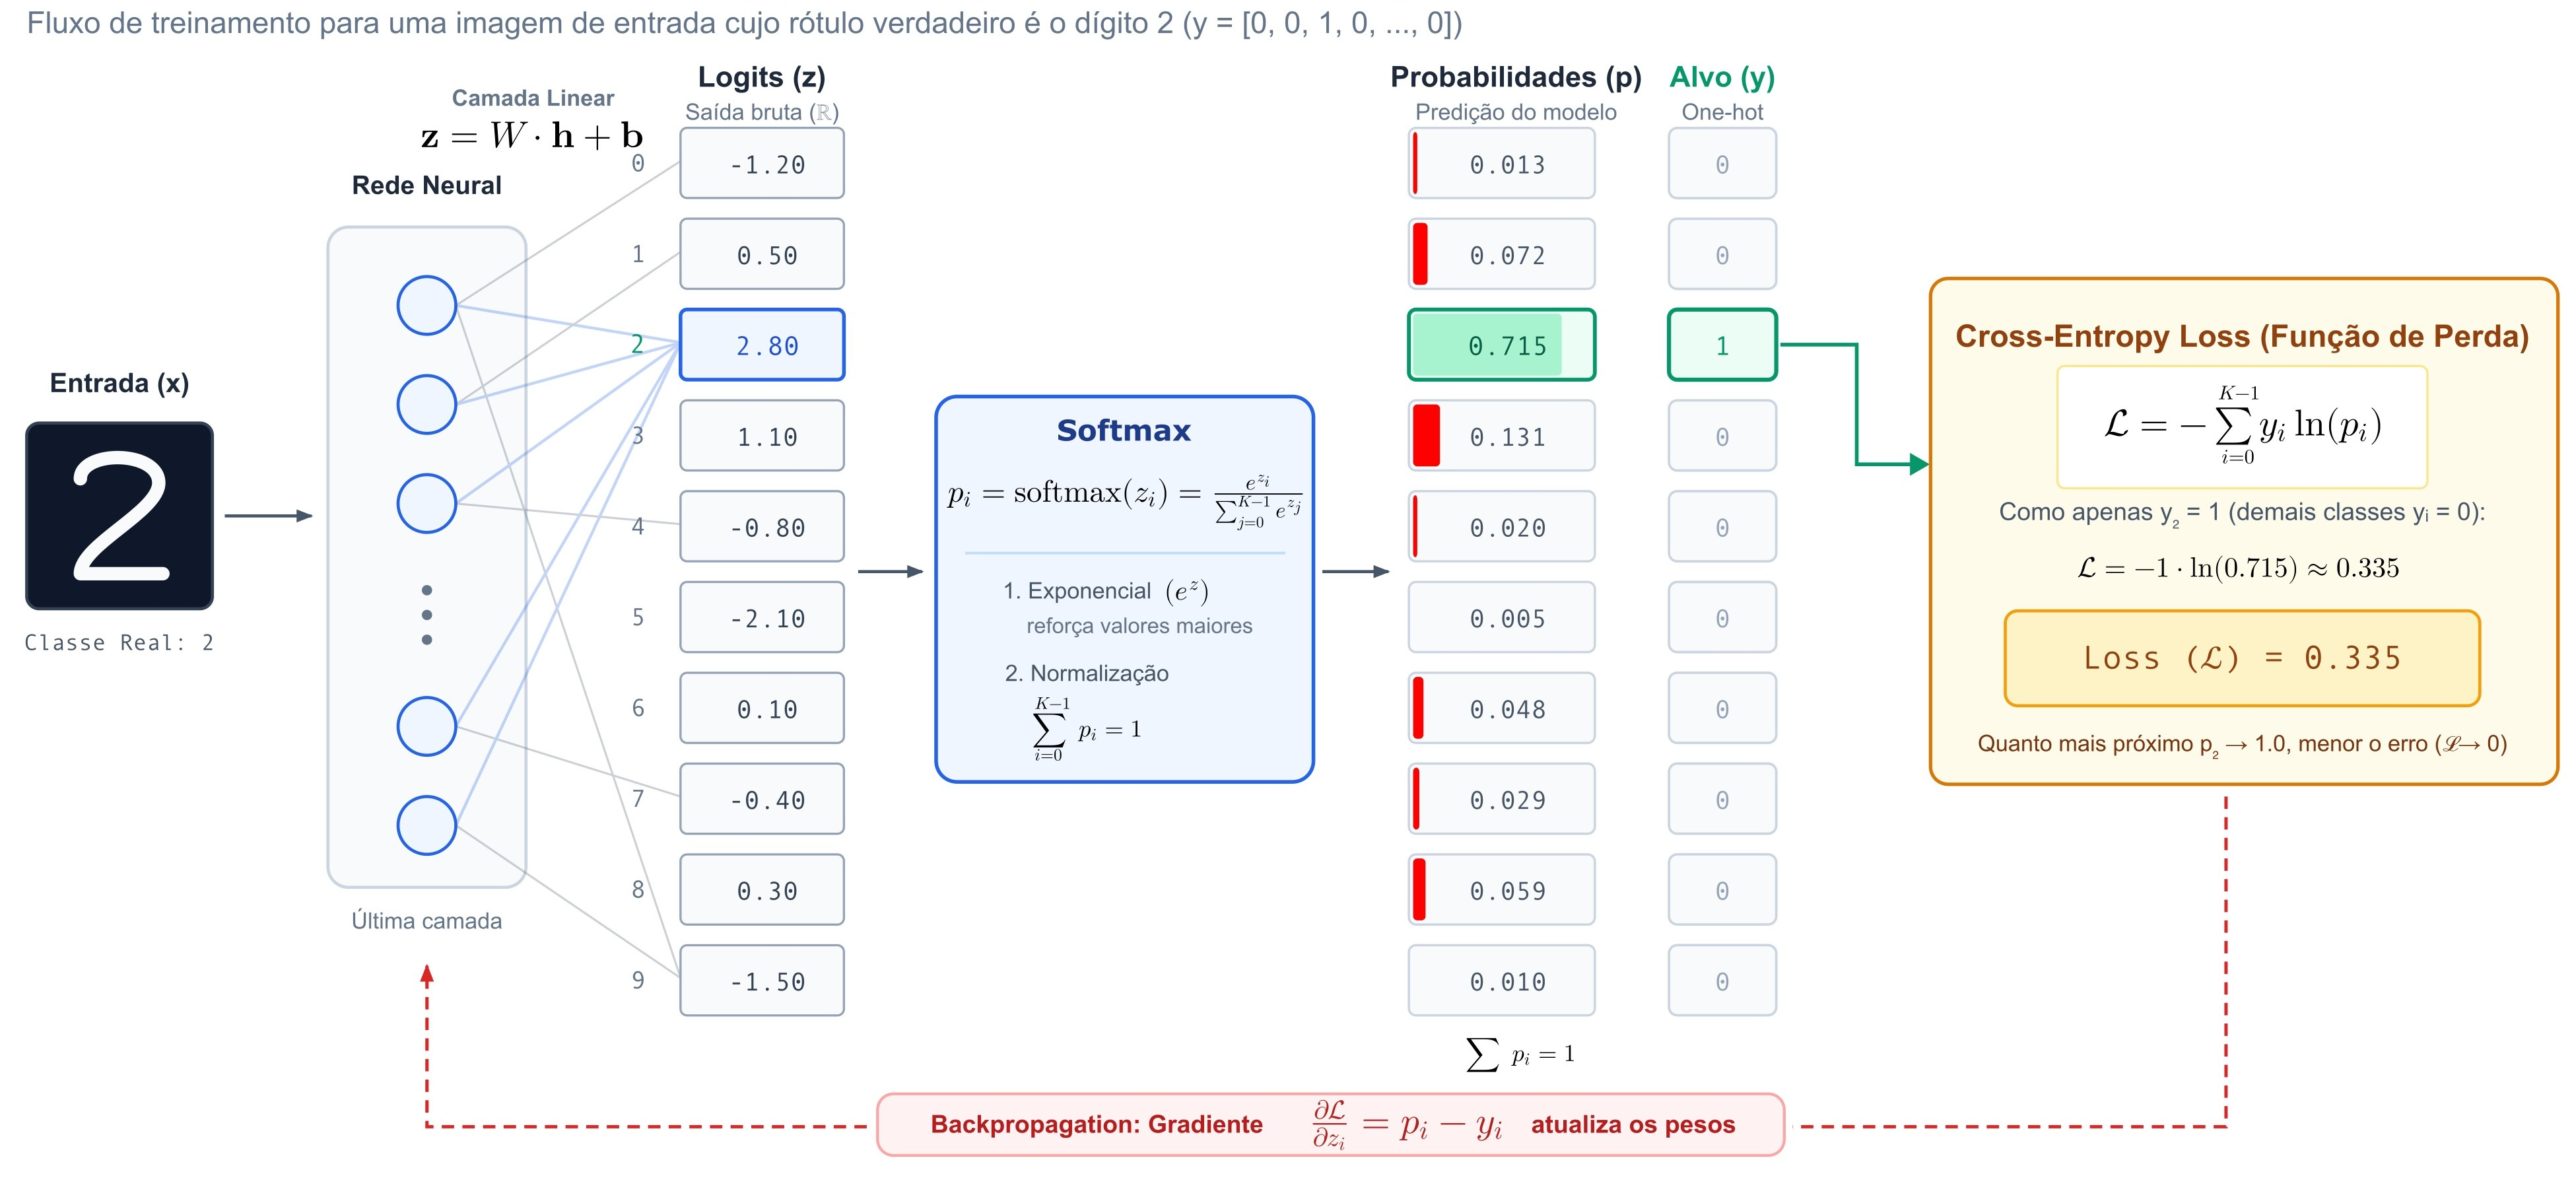

# Convolução de Imagens


Acesse também: https://cs231n.github.io/convolutional-networks/

Na Visão Computacional e DL, a **convolução** é uma operação matemática usada para extrair características locais (como bordas, texturas e formas) de uma imagem. Ela funciona deslizando uma pequena matriz de pesos — chamada de **filtro** ou **kernel** (por exemplo, $3 \times 3$ ou $2 \times 2$) — passo a passo sobre toda a imagem de entrada.

Em cada posição, o filtro multiplica seus valores pelos pixels correspondentes da região e soma todos os resultados (produto escalar), gerando um único pixel em uma nova matriz chamada **mapa de características** (_feature map_).

Enquanto filtros fixos clássicos aplicam efeitos específicos (como realçar bordas ou borrar a imagem), nas Redes Neurais Convolucionais (CNNs) os valores desses filtros são aprendidos automaticamente durante o treinamento para identificar os padrões mais úteis para a tarefa.


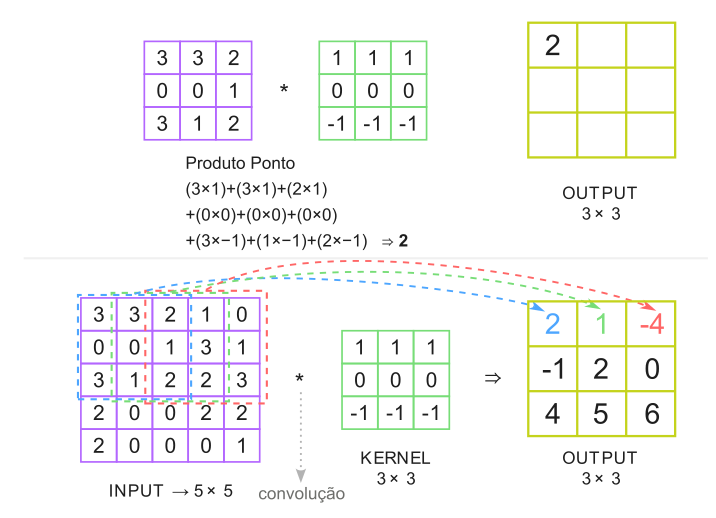

## Exemplo 1
Demonstração prática de como um filtro (*kernel* $3 \times 3$, neste caso um detector de bordas Laplaciano) desliza sobre uma imagem aplicando produto escalar local.

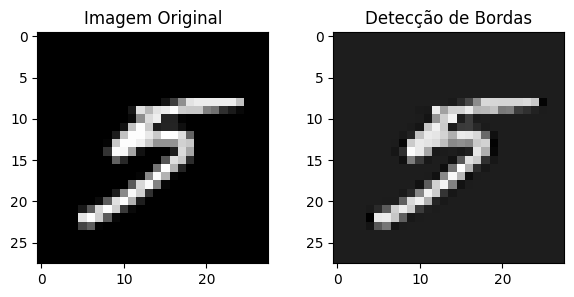

In [7]:
# 1. Escolher um dígito aleatório para visualização
image_index = np.random.randint(0, len(x_test))
image = x_test[image_index]

# 2. Definir o kernel de detecção de bordas (Laplaciano)
kernel = np.array([[-1, -1, -1],
                  [-1,  8, -1],
                  [-1, -1, -1]])

# 3. Formatar a imagem e o kernel para convolução
# Converte para float32
image = image.astype(np.float32)
kernel = kernel.astype(np.float32)

# Adiciona dimensões de batch e canais
image = np.expand_dims(image, axis=0) # (1, 28, 28)
image = np.expand_dims(image, axis=-1) # (1, 28, 28, 1)

kernel = np.expand_dims(kernel, axis=-1) # (3, 3, 1)
kernel = np.expand_dims(kernel, axis=-1) # (3, 3, 1, 1)

# 4. Convolução usando tf.nn.conv2d
convolved_image = tf.nn.conv2d(
    image,
    kernel,
    strides=1,
    padding='SAME'  # Mantem o tamanho da saída igual à entrada (1, 28, 28, 1)
)

# 5. Visualizar a imagem original e o resultado da convolução
plt.figure(figsize=(7, 3))

plt.subplot(1, 2, 1)
plt.imshow(np.squeeze(image), cmap='gray') # Remove as dimensões extras para plotar -> (28, 28)
plt.title("Imagem Original")

plt.subplot(1, 2, 2)
plt.imshow(np.squeeze(convolved_image), cmap='gray') # Remove as dimensões extras para plotar -> (28, 28)
plt.title("Detecção de Bordas")

plt.show()

## Exemplo 2
outro exemplo de detecção de bordas

228813984/228813984 ━━━━━━━━━━━━━━━━━━━━ 13s 0us/step


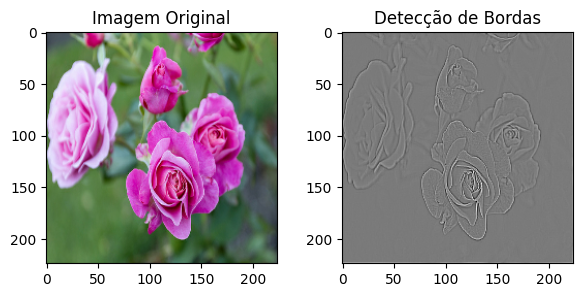

In [8]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import pathlib
import os

# 1. Carregar uma imagem de exemplo do dataset de flores
data_dir = tf.keras.utils.get_file('flower_photos','https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz', untar=True)
data_dir = pathlib.Path(data_dir)

# Obter a lista de todas as imagens (roses)
root = '/root/.keras/datasets/flower_photos/flower_photos/roses'
image_files = os.listdir(root)

# Escolher uma imagem aleatória
image_path = str(np.random.choice(image_files))

# 2. Carregar e pré-processar a imagem
def load_and_preprocess_image(image_path):
    image = tf.io.read_file(image_path)
    image = tf.image.decode_jpeg(image, channels=3) # Decodifica como JPEG (3 canais de cor)
    image = tf.image.convert_image_dtype(image, tf.float32) # Converte para float32 e normaliza para [0, 1]
    image = tf.image.resize(image, [224, 224]) # Redimensiona para um tamanho fixo (opcional, mas recomendado)
    return image

image = load_and_preprocess_image(os.path.join(root,image_path))

# 3. Definir o kernel de detecção de bordas (Laplaciano)
kernel = np.array([[-1, -1, -1],
                  [-1,  8, -1],
                  [-1, -1, -1]])

# 4. Formatar a imagem e o kernel para convolução
# Converte para numpy array e garante que seja float32
image = image.numpy().astype(np.float32)
kernel = kernel.astype(np.float32)

# Adiciona dimensões de batch
image = np.expand_dims(image, axis=0) # (1, 224, 224, 3)
kernel = np.expand_dims(kernel, axis=-1) # (3, 3, 1)
kernel = np.expand_dims(kernel, axis=-1) # (3, 3, 1, 1)

# Repete o kernel para que corresponda ao número de canais de entrada (RGB)
kernel = np.repeat(kernel, 3, axis=2)  # (3, 3, 3, 1)

# 5. Convolução usando tf.nn.conv2d
convolved_image = tf.nn.conv2d(
    image,
    kernel,
    strides=1,
    padding='SAME'
)

# 6. Visualizar a imagem original e o resultado da convolução
plt.figure(figsize=(7, 3))

plt.subplot(1, 2, 1)
plt.imshow(np.squeeze(image))
plt.title("Imagem Original")

plt.subplot(1, 2, 2)
plt.imshow(np.squeeze(convolved_image), cmap='gray')
plt.title("Detecção de Bordas")

plt.show()

## Exemplo 3
vejamos outro exemplo aplicando borramento da imagem

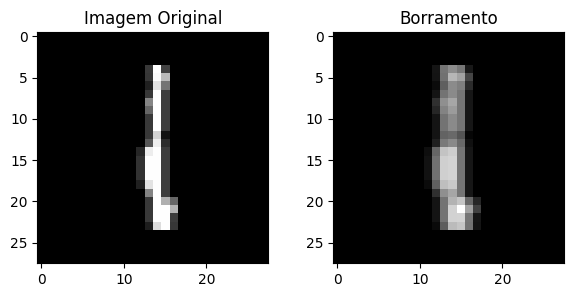

In [9]:
# 1. Escolher um dígito aleatório para visualização
image_index = np.random.randint(0, len(x_test))
image = x_test[image_index]

# 2. Definir o kernel de borramento (média 3x3)
kernel = np.array([[1/9, 1/9, 1/9],
                   [1/9, 1/9, 1/9],
                   [1/9, 1/9, 1/9]])

# 3. Formatar a imagem e o kernel para convolução
image = image.astype(np.float32)
kernel = kernel.astype(np.float32)

# Adiciona dimensões de batch e canais -> image: (1, 28, 28, 1), kernel: (3, 3, 1, 1)
image = np.expand_dims(image, axis=0) # (1, 28, 28)
image = np.expand_dims(image, axis=-1) # (1, 28, 28, 1)
kernel = np.expand_dims(kernel, axis=-1) # (3, 3, 1)
kernel = np.expand_dims(kernel, axis=-1) # (3, 3, 1, 1)

# 4. Convolução usando tf.nn.conv2d -> saída shape (1, 28, 28, 1)
convolved_image = tf.nn.conv2d(
    image,
    kernel,
    strides=1,
    padding='SAME'
)

# 5. Visualizar a imagem original e o resultado da convolução
plt.figure(figsize=(7, 3))

plt.subplot(1, 2, 1)
plt.imshow(np.squeeze(image), cmap='gray')
plt.title("Imagem Original")

plt.subplot(1, 2, 2)
plt.imshow(np.squeeze(convolved_image), cmap='gray')
plt.title("Borramento")

plt.show()

# `Conv2D` : Camada Convolucional

A operação realizada por uma camada convolucional é sempre, inicialmente, uma
**combinação linear** entre os valores dos **pixels** da entrada e os pesos do **kernel** (
e portanto somada a um termo de bias). Para cada posição $(i,j)$ e para cada filtro $k$, o valor
produzido pela convolução é:

$$
z_{i,j}^{(k)} = \sum_{m,n,c} X_{i+m,\; j+n,\; c}\;
W_{m,n,c}^{(k)} + b^{(k)}
$$

Essa expressão representa a parte **linear** da operação. Se a camada convolucional utiliza uma função de ativação, como a **ReLU**, então o valor
final produzido é:

$$
\mathrm{ReLU}\left(z_{i,j}^{(k)}\right)
=
\max(0,\; z_{i,j}^{(k)})
$$

A convolução em si é linear, mas a função de ativação é **essencial** para produzir a **não linearidade no modelo**.


# MaxPooling2D, Padding e Stride

## Padding

`padding` controla as dimensões de saída da convolução, preservando detalhes nas bordas e facilitando o design da rede. Por padrão o `padding='valid'` é sem prenchimento algum para o `Conv2D` no Keras, mas existem outros tipos de `padding` no PyTorch:

- **Zero Padding**: preenchimento com zeros
```
[ 0 | 0   0   0 | 0 ]
---------------------
[ 0 | 1   2   3 | 0 ]
[ 0 | 4   5   6 | 0 ]
[ 0 | 7   8   9 | 0 ]
---------------------
[ 0 | 0   0   0 | 0 ]
```
- **Reflect**: espelha em relação ao eixo da borda
```
[ 5 | 4   5   6 | 5 ]
---------------------
[ 2 | 1   2   3 | 2 ]
[ 5 | 4   5   6 | 5 ]
[ 8 | 7   8   9 | 8 ]
---------------------
[ 5 | 4   5   6 | 5 ]
```
- **Replicate**: repetição do valor exato da borda
```
[ 1 | 1   2   3 | 3 ]
---------------------
[ 1 | 1   2   3 | 3 ]
[ 4 | 4   5   6 | 6 ]
[ 7 | 7   8   9 | 9 ]
---------------------
[ 7 | 7   8   9 | 9 ]
```
- **Circular**: faz um wrap-around ("toróide")
```
[ 9 | 7   8   9 | 7 ]
---------------------
[ 3 | 1   2   3 | 1 ]
[ 6 | 4   5   6 | 4 ]
[ 9 | 7   8   9 | 7 ]
---------------------
[ 3 | 1   2   3 | 1 ]
```

## Stride

O **`stride`** (passo) define o número de pixels que o filtro (*kernel*) desloca a cada movimento sobre a entrada. Ele controla o nível de **subamostragem espacial** (*downsampling*) da convolução:

- **`stride = 1` (padrão):** O filtro desliza pixel a pixel, preservando a resolução espacial máxima (quando combinado com `padding='same'`).
- **`stride = 2` (ou maior):** O filtro salta posições intermediárias, reduzindo a altura e a largura do mapa de características pela metade (efeito semelhante ao *pooling*, porém com pesos aprendíveis).

### Dimensão de Saída (combinando `padding` e `stride`)

Para uma entrada de tamanho $W$, kernel $K$, padding $P$ e stride $S$, a dimensão de saída $O$ é dada por:

$$O = \left\lfloor \frac{W - K + 2P}{S} \right\rfloor + 1$$

*Ex:* Uma entrada $28 \times 28$ com kernel $3 \times 3$, `padding = 1` e `stride = 2` gera uma saída ($O =\lfloor(28 - 3 + 2)/2\rfloor + 1 = 14$), ou seja $14 \times 14$.

Exemplos

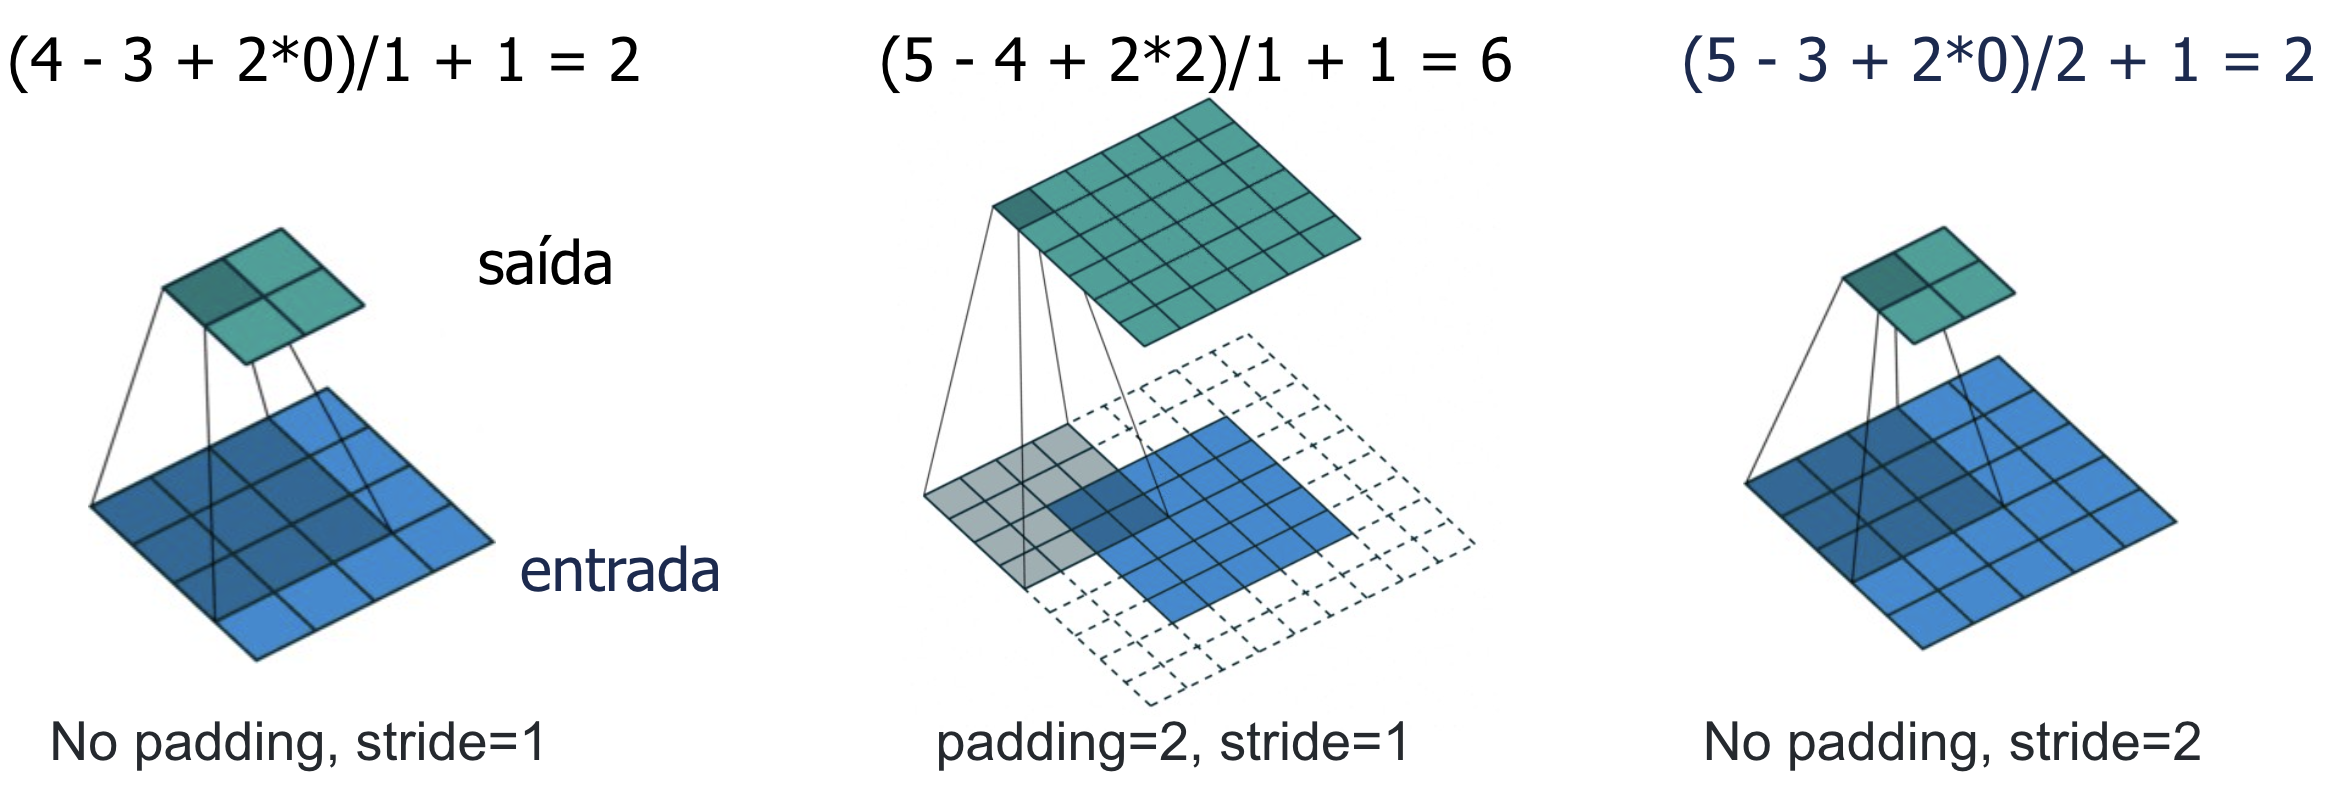

In [10]:
import tensorflow as tf
from tensorflow.keras.layers import Conv2D

# Imagem de entrada de exemplo (batch_size, height, width, channels)
input_shape = (1, 28, 28, 1)
input_tensor = tf.random.normal(input_shape)

# Camada convolucional SEM padding (padrão padding='valid')
conv_layer = Conv2D(filters=32, kernel_size=(3, 3), activation='relu')
output_tensor = conv_layer(input_tensor)

#padding=0, kernel=3, stride=1
#O =[(28 - 3 + 2x0)/1] + 1] = 26
print("Input shape:", input_tensor.shape)    # Output: Input shape: (1, 28, 28, 1)
print("Output shape:", output_tensor.shape)  # Output: Output shape: (1, 26, 26, 32) (height e width reduzem de 28 para 26)

# Camada convolucional COM padding 'same'
conv_layer = Conv2D(filters=32, kernel_size=(3, 3), activation='relu', padding='same')
output_tensor = conv_layer(input_tensor)

#padding=1, kernel=3, stride=1
#O =[(28 - 3 + 2x1)/1] + 1] = 28
print("Input shape:", input_tensor.shape)    # Output: Input shape: (1, 28, 28, 32) (height e width permanecem os mesmos)
print("Output shape:", output_tensor.shape)


Input shape: (1, 28, 28, 1)
Output shape: (1, 26, 26, 32)
Input shape: (1, 28, 28, 1)
Output shape: (1, 28, 28, 32)


## MaxPooling

O **`MaxPooling2D`** realiza uma **subamostragem espacial** (*downsampling*) nos mapas de características, reduzindo sua dimensionalidade e retendo apenas as informações mais relevantes.

Uma janela deslizante (geralmente $2 \times 2$ com `stride = 2`) percorre cada canal do mapa de características e seleciona **apenas o valor máximo** de cada região, descartando os demais:

$$\begin{bmatrix} 1 & 3 \\ 8 & 2 \end{bmatrix} \xrightarrow{\text{MaxPool } 2\times2} \begin{bmatrix} 8 \end{bmatrix}$$


In [11]:
import tensorflow as tf
from tensorflow.keras.layers import MaxPooling2D

# Tensor de entrada de exemplo: (batch_size, height, width, channels)
input_tensor = tf.random.normal((1, 28, 28, 1))

# MaxPooling 2x2 (por padrão, strides=(2, 2) e padding='valid')
pooling_layer = MaxPooling2D(pool_size=(2, 2))
output_tensor = pooling_layer(input_tensor)

print("Input shape:", input_tensor.shape)    # Output: (1, 28, 28, 1)
print("Output shape:", output_tensor.shape)  # Output: (1, 14, 14, 1) (reduz height e width pela metade)

# Exemplo com dimensão ímpar (13x13) para evidenciar o efeito de padding='same' vs 'valid'
odd_tensor = tf.random.normal((1, 13, 13, 1))
print("Saída 13x13 (valid):", MaxPooling2D((2, 2), padding='valid')(odd_tensor).shape)  # (1, 6, 6, 1) - descarta borda
print("Saída 13x13 (same):",  MaxPooling2D((2, 2), padding='same')(odd_tensor).shape)   # (1, 7, 7, 1) - completa borda

Input shape: (1, 28, 28, 1)
Output shape: (1, 14, 14, 1)
Saída 13x13 (valid): (1, 6, 6, 1)
Saída 13x13 (same): (1, 7, 7, 1)


# `Dropout2D`: *Spatial Dropout*

Em CNNs, pixels vizinhos dentro de um mesmo mapa de características (*feature map*) são fortemente correlacionados. Por isso, o *dropout* tradicional — que zera pixels individuais de forma aleatória — perde eficácia, já que a rede consegue facilmente recuperar a informação perdida a partir dos pixels adjacentes.

O **`Dropout2D`** resolve esse problema zerando **canais (*feature maps*) inteiros** durante o treinamento com probabilidade $p$ (ex.: $0.25$ ou $0.5$). Dessa forma, a rede é forçada a não depender excessivamente de filtros específicos, promovendo maior independência entre as representações aprendidas e reduzindo o *overfitting*.

# Keras ConvNet + Regularização (Dropout)

Adicionamos camadas `Dropout` após o *MaxPooling* e antes da saída para reduzir o sobreajuste (*overfitting*), além de uma camada densa intermediária de `128` neurônios.


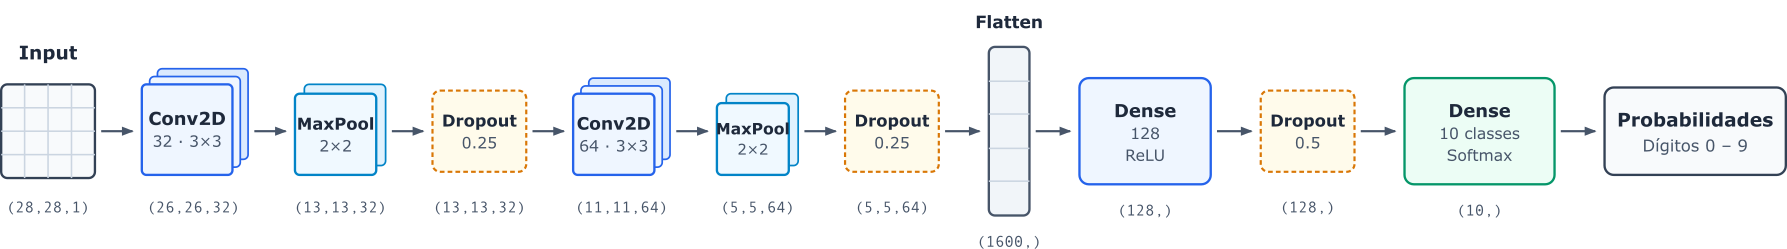

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 63s 33ms/step - accuracy: 0.9211 - loss: 0.2546 - val_accuracy: 0.9834 - val_loss: 0.0536
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 62s 33ms/step - accuracy: 0.9704 - loss: 0.1008 - val_accuracy: 0.9865 - val_loss: 0.0372
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 63s 33ms/step - accuracy: 0.9758 - loss: 0.0800 - val_accuracy: 0.9885 - val_loss: 0.0331
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 61s 33ms/step - accuracy: 0.9800 - loss: 0.0674 - val_accuracy: 0.9880 - val_loss: 0.0394
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 82s 33ms/step - accuracy: 0.9823 - loss: 0.0584 - val_accuracy: 0.9900 - val_loss: 0.0267


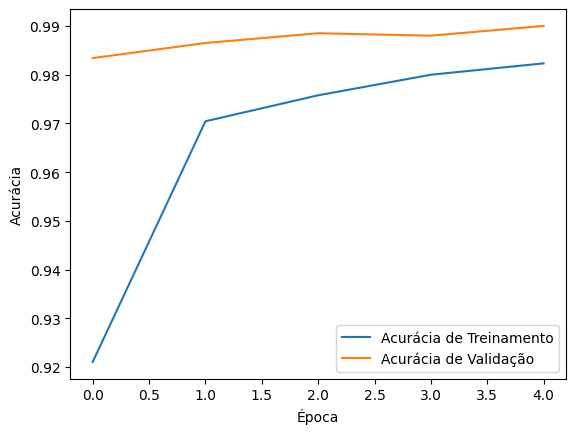

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step
              precision    recall  f1-score   support

           0       1.00      0.99      1.00       980
           1       0.99      1.00      0.99      1135
           2       0.98      0.99      0.99      1032
           3       0.99      0.99      0.99      1010
           4       1.00      0.99      0.99       982
           5       0.99      0.99      0.99       892
           6       0.99      0.99      0.99       958
           7       0.98      0.99      0.98      1028
           8       0.99      0.99      0.99       974
           9       0.99      0.98      0.99      1009

    accuracy                           0.99     10000
   macro avg       0.99      0.99      0.99     10000
weighted avg       0.99      0.99      0.99     10000

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step


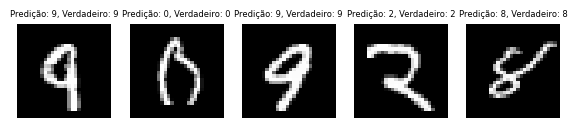

In [12]:
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import classification_report

# Carrega o dataset MNIST
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

# Normaliza os dados de entrada a [0,1]
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

# Adiciona uma dimensão para o canal (convoluções esperam imagens com 3 dimensões) -> (N, 28, 28, 1)
x_train = np.expand_dims(x_train, -1)
x_test  = np.expand_dims(x_test, -1)

# Define o modelo convolucional com Dropout
model = tf.keras.Sequential([
    tf.keras.layers.Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Dropout(0.25),
    tf.keras.layers.Conv2D(64, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Dropout(0.25),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(10, activation='softmax')
])

# Compila o modelo
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

# Treina o modelo
history = model.fit(x_train, y_train, epochs=5, validation_data=(x_test, y_test))

# Plota o gráfico do treinamento
plt.plot(history.history['accuracy'], label='Acurácia de Treinamento')
plt.plot(history.history['val_accuracy'], label='Acurácia de Validação')
plt.xlabel('Época')
plt.ylabel('Acurácia')
plt.legend()
plt.show()

# Avalia o modelo
predictions = model.predict(x_test)
predicted_labels = np.argmax(predictions, axis=1)
print(classification_report(y_test, predicted_labels))

# Faz predições para algumas instâncias aleatorias e exibe as imagens
indices = np.random.choice(len(x_test), 5, replace=False)
predictions = model.predict(x_test[indices])

plt.figure(figsize=(7,2))
for i, idx in enumerate(indices):
    predicted_label = np.argmax(predictions[i])
    true_label = y_test[idx]
    ax = plt.subplot(1,5,i+1)
    plt.imshow(x_test[idx].reshape(28, 28), cmap='gray')
    plt.title(f"Predição: {predicted_label}, Verdadeiro: {true_label}",fontsize=6)
    plt.axis("off")
plt.show()


# Batch Normalization

A normalização em lote (`BatchNormalization`) estabiliza a distribuição das ativações entre as camadas durante o treino, acelerando a convergência e permitindo o uso seguro de taxas de aprendizado mais altas.


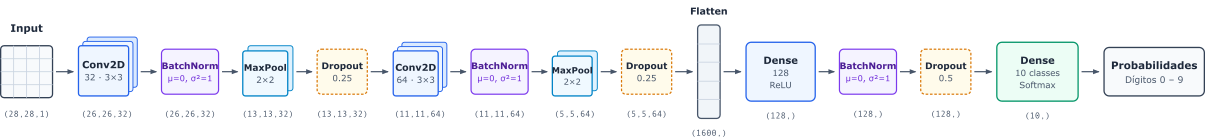

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 86s 45ms/step - accuracy: 0.9382 - loss: 0.2013 - val_accuracy: 0.9838 - val_loss: 0.0505
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 145s 46ms/step - accuracy: 0.9721 - loss: 0.0905 - val_accuracy: 0.9889 - val_loss: 0.0346
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 87s 46ms/step - accuracy: 0.9775 - loss: 0.0717 - val_accuracy: 0.9886 - val_loss: 0.0350
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 83s 44ms/step - accuracy: 0.9800 - loss: 0.0650 - val_accuracy: 0.9898 - val_loss: 0.0283
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 144s 45ms/step - accuracy: 0.9827 - loss: 0.0564 - val_accuracy: 0.9919 - val_loss: 0.0255


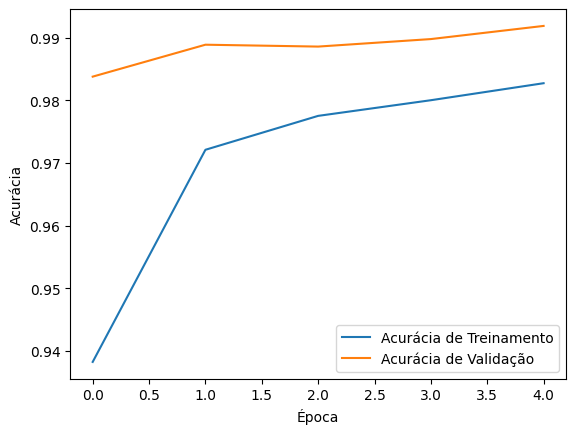

313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step
              precision    recall  f1-score   support

           0       0.99      1.00      0.99       980
           1       0.99      1.00      0.99      1135
           2       0.99      0.99      0.99      1032
           3       0.99      0.99      0.99      1010
           4       0.99      0.99      0.99       982
           5       0.99      0.99      0.99       892
           6       0.99      0.99      0.99       958
           7       0.99      0.99      0.99      1028
           8       0.99      0.99      0.99       974
           9       0.99      0.98      0.99      1009

    accuracy                           0.99     10000
   macro avg       0.99      0.99      0.99     10000
weighted avg       0.99      0.99      0.99     10000

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step


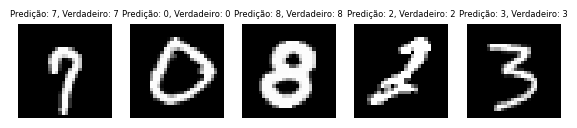

In [13]:
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import classification_report

# Carrega o dataset MNIST
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

# Normaliza os dados de entrada a [0,1]
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

# Adiciona uma dimensão para o canal (convoluções esperam imagens com 3 dimensões) -> (N, 28, 28, 1)
x_train = np.expand_dims(x_train, -1)
x_test  = np.expand_dims(x_test, -1)

# Define o modelo convolucional com BatchNormalization e Dropout
model = tf.keras.Sequential([
    tf.keras.layers.Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Dropout(0.25),

    tf.keras.layers.Conv2D(64, (3, 3), activation='relu'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Dropout(0.25),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(10, activation='softmax')
])

# Compila o modelo
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

# Treina o modelo
history = model.fit(x_train, y_train, epochs=5, validation_data=(x_test, y_test))

# Plota o gráfico do treinamento
plt.plot(history.history['accuracy'], label='Acurácia de Treinamento')
plt.plot(history.history['val_accuracy'], label='Acurácia de Validação')
plt.xlabel('Época')
plt.ylabel('Acurácia')
plt.legend()
plt.show()

# Avalia o modelo
predictions = model.predict(x_test)
predicted_labels = np.argmax(predictions, axis=1)
print(classification_report(y_test, predicted_labels))

# Faz predições para algumas instâncias aleatorias e exibe as imagens
indices = np.random.choice(len(x_test), 5, replace=False)
predictions = model.predict(x_test[indices])

plt.figure(figsize=(7,2))
for i, idx in enumerate(indices):
    predicted_label = np.argmax(predictions[i])
    true_label = y_test[idx]
    ax = plt.subplot(1,5,i+1)
    plt.imshow(x_test[idx].reshape(28, 28), cmap='gray')
    plt.title(f"Predição: {predicted_label}, Verdadeiro: {true_label}",fontsize=6)
    plt.axis("off")
plt.show()


# Outras curiosidades

CNN Explainer https://poloclub.github.io/cnn-explainer/

2D fully-connected network visualization https://adamharley.com/nn_vis/mlp/2d.html

2D convolutional network visualization https://adamharley.com/nn_vis/cnn/2d.html